In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

target_actions = [
    "sub_car_claim_click",
    "sub_car_claim_submit_click",
    "sub_open_dialog_click",
    "sub_custom_question_submit_click",
    "sub_call_number_click",
    "sub_callback_submit_click",
    "sub_submit_success",
    "sub_car_request_submit_click"
]

In [3]:
sessions = pd.read_csv('/Users/rostislavshigapov/Desktop/MLeng/Final Work/data/ga_sessions.csv', low_memory=False)
hits = pd.read_csv('/Users/rostislavshigapov/Desktop/MLeng/Final Work/data/ga_hits.csv')
print(sessions.shape, hits.shape, sep="\n")
display(sessions.head())
display(hits.head())

(1860042, 18)
(15726470, 11)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Zlatoust
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,mobile,Android,Samsung,NaN,385x854,Samsung Internet,Russia,Moscow
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Krasnoyarsk
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,NaN,NOBKLgtuvqYWkXQHeYWM,NaN,mobile,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,NaN,NaN,NaN,mobile,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow


,session_id,hit_date,hit_time,hit_number,hit_type,hit_referer,hit_page_path,event_category,event_action,event_label,event_value
0,5639623078712724064.1640254056.1640254056,2021-12-23,597864.0,30,event,NaN,sberauto.com/cars?utm_source_initial=google&ut...,quiz,quiz_show,NaN,NaN
1,7750352294969115059.1640271109.1640271109,2021-12-23,597331.0,41,event,NaN,sberauto.com/cars/fiat?city=1&city=18&rental_c...,quiz,quiz_show,NaN,NaN
2,885342191847998240.1640235807.1640235807,2021-12-23,796252.0,49,event,NaN,sberauto.com/cars/all/volkswagen/polo/e994838f...,quiz,quiz_show,NaN,NaN
3,142526202120934167.1640211014.1640211014,2021-12-23,934292.0,46,event,NaN,sberauto.com/cars?utm_source_initial=yandex&ut...,quiz,quiz_show,NaN,NaN
4,3450086108837475701.1640265078.1640265078,2021-12-23,768741.0,79,event,NaN,sberauto.com/cars/all/mercedes-benz/cla-klasse...,quiz,quiz_show,NaN,NaN


In [4]:
sessions.columns = sessions.columns.str.strip()
hits.columns = hits.columns.str.strip()

sessions = sessions.drop_duplicates()
hits = hits.drop_duplicates()

for df in [sessions, hits]:
    for col in df.columns:
        if df[col].dtype == "object":
            df[col] = df[col].replace("", np.nan)

print("sessions duplicates:", sessions.duplicated().sum())
print("hits duplicates:", hits.duplicated().sum())

sessions duplicates: 0
hits duplicates: 0


In [5]:
sessions["visit_date"] = pd.to_datetime(sessions["visit_date"], format='%Y-%m-%d', errors="coerce")
hits["hit_date"] = pd.to_datetime(hits["hit_date"], format='%Y-%m-%d', errors="coerce")
sessions["visit_time"] = pd.to_datetime(sessions["visit_time"].astype(str), format='%H:%M:%S',errors="coerce")

sessions[["visit_date"]].info()
hits[["hit_date"]].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1860042 entries, 0 to 1860041
Data columns (total 1 columns):
 #   Column      Dtype         
---  ------      -----         
 0   visit_date  datetime64[ns]
dtypes: datetime64[ns](1)
memory usage: 14.2 MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15726470 entries, 0 to 15726469
Data columns (total 1 columns):
 #   Column    Dtype         
---  ------    -----         
 0   hit_date  datetime64[ns]
dtypes: datetime64[ns](1)
memory usage: 120.0 MB


In [6]:
target = (
    hits.assign(is_target=hits["event_action"].isin(target_actions).astype(int))
        .groupby("session_id", as_index=False)["is_target"]
        .max()
        .rename(columns={"is_target": "target"})
)

target["target"].value_counts(normalize=True)

target
0    0.970737
1    0.029263
Name: proportion, dtype: float64

In [7]:
missing_sessions = (sessions.isna().mean().sort_values(ascending=False) * 100).to_frame("missing_%")
missing_hits = (hits.isna().mean().sort_values(ascending=False) * 100).to_frame("missing_%")

display(missing_sessions.head(20))
display(missing_hits.head(20))

,missing_%
device_model,99.121633
utm_keyword,58.174009
device_os,57.533002
device_brand,19.740307
utm_adcontent,18.043410
utm_campaign,11.806346
utm_source,0.005215
geo_country,0.000000
device_browser,0.000000
device_screen_resolution,0.000000


,missing_%
event_value,100.000000
hit_time,58.247795
hit_referer,39.899634
event_label,23.909905
session_id,0.000000
hit_date,0.000000
hit_number,0.000000
hit_type,0.000000
hit_page_path,0.000000
event_category,0.000000


In [8]:
def drop_empty_columns(df, threshold=0.95):
    empty_share = df.isna().mean()
    cols_to_drop = empty_share[empty_share >= threshold].index.tolist()
    return df.drop(columns=cols_to_drop), cols_to_drop

sessions_clean, dropped_sessions_cols = drop_empty_columns(sessions, threshold=0.95)
hits_clean, dropped_hits_cols = drop_empty_columns(hits, threshold=0.95)

print("dropped sessions cols:", dropped_sessions_cols)
print("dropped hits cols:", dropped_hits_cols)

dropped sessions cols: ['device_model']
dropped hits cols: ['event_value']


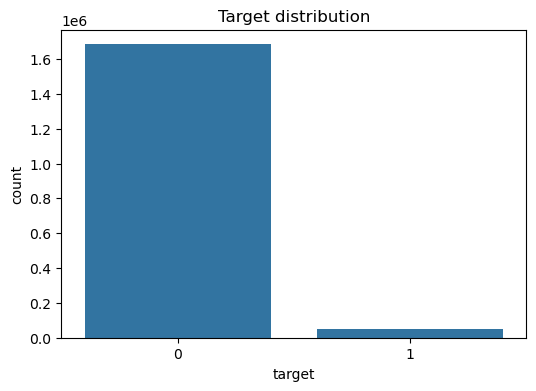

target
0    1683850
1      50760
Name: count, dtype: int64
target
0    0.970737
1    0.029263
Name: proportion, dtype: float64


In [9]:
plt.figure(figsize=(6, 4))
sns.countplot(x="target", data=target)
plt.title("Target distribution")
plt.show()

print(target["target"].value_counts())
print(target["target"].value_counts(normalize=True))

In [10]:
hits_clean["is_target_action"] = hits_clean["event_action"].isin(target_actions).astype(int)

hits_agg = hits_clean.groupby("session_id").agg(
    hits_cnt=("hit_number", "count"),
    unique_pages=("hit_page_path", "nunique"),
    unique_actions=("event_action", "nunique"),
    target_hits_cnt=("is_target_action", "sum")
).reset_index()

hits_agg.head()

,session_id,hits_cnt,unique_pages,unique_actions,target_hits_cnt
0,1000009318903347362.1632663668.1632663668,10,3,6,0
1,1000010177899156286.1635013443.1635013443,6,2,5,0
2,1000013386240115915.1635402956.1635402956,11,3,6,0
3,1000017303238376207.1623489300.1623489300,12,3,8,0
4,1000020580299877109.1624943350.1624943350,1,1,1,0


In [11]:
df = sessions_clean.merge(target, on="session_id", how="left")
df = df.merge(hits_agg, on="session_id", how="left")

df["target"] = df["target"].fillna(0).astype(int)

df.shape
display(df.head())

,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,device_brand,device_screen_resolution,device_browser,geo_country,geo_city,target,hits_cnt,unique_pages,unique_actions,target_hits_cnt
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,1900-01-01 14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,Huawei,360x720,Chrome,Russia,Zlatoust,0,2.0,1.0,2.0,0.0
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,1900-01-01 08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,Samsung,385x854,Samsung Internet,Russia,Moscow,0,1.0,1.0,1.0,0.0
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,1900-01-01 02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,Huawei,360x720,Chrome,Russia,Krasnoyarsk,0,16.0,2.0,3.0,0.0
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,1900-01-01 05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,NaN,NOBKLgtuvqYWkXQHeYWM,NaN,...,Xiaomi,393x786,Chrome,Russia,Moscow,0,3.0,1.0,2.0,0.0
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,1900-01-01 05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,NaN,NaN,NaN,...,Xiaomi,393x786,Chrome,Russia,Moscow,0,2.0,1.0,2.0,0.0


In [12]:
for col in df.columns:
    if df[col].dtype == "object":
        df[col] = df[col].replace("", np.nan)

num_cols = df.select_dtypes(include=[np.number]).columns
obj_cols = df.select_dtypes(include=["object"]).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

for col in obj_cols:
    df[col] = df[col].fillna("missing")

df.isna().sum().sort_values(ascending=False).head(20)

session_id                  0
client_id                   0
unique_actions              0
unique_pages                0
hits_cnt                    0
target                      0
geo_city                    0
geo_country                 0
device_browser              0
device_screen_resolution    0
device_brand                0
device_os                   0
device_category             0
utm_keyword                 0
utm_adcontent               0
utm_campaign                0
utm_medium                  0
utm_source                  0
visit_number                0
visit_time                  0
dtype: int64

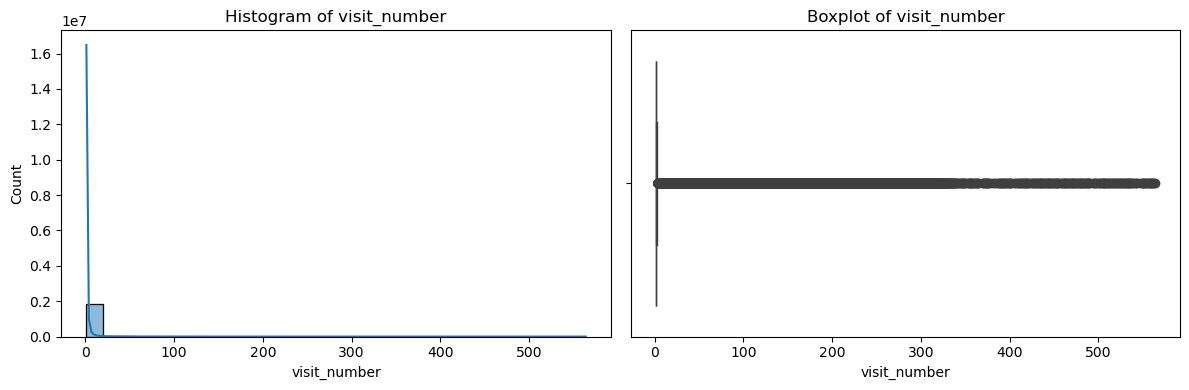

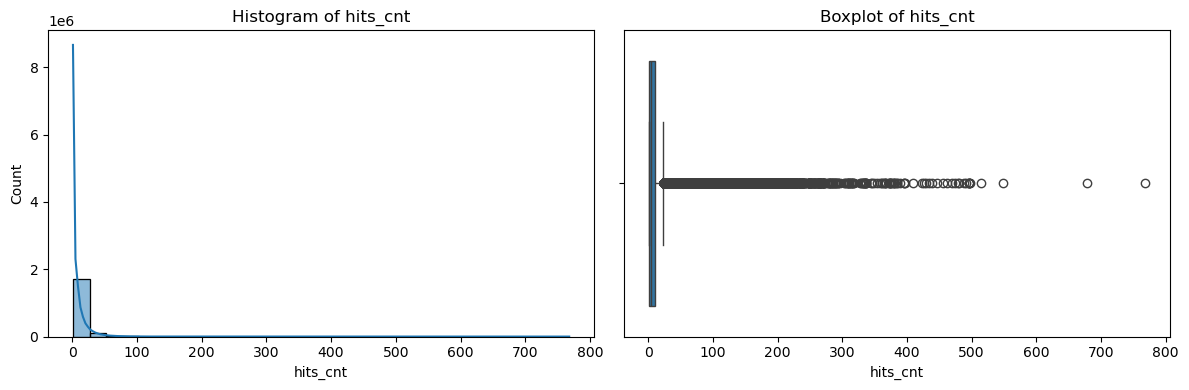

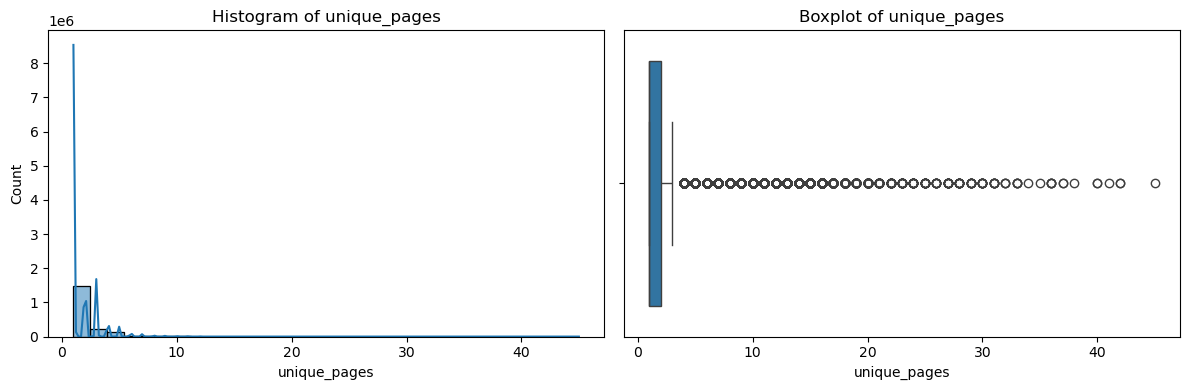

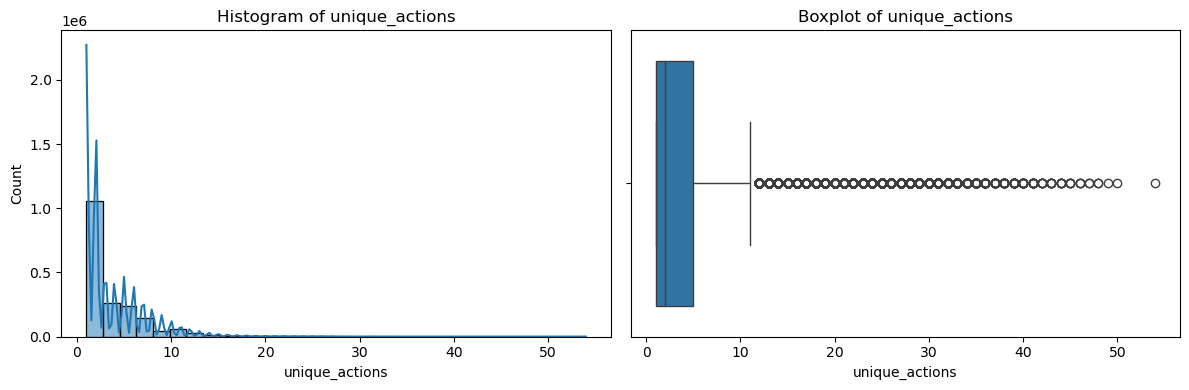

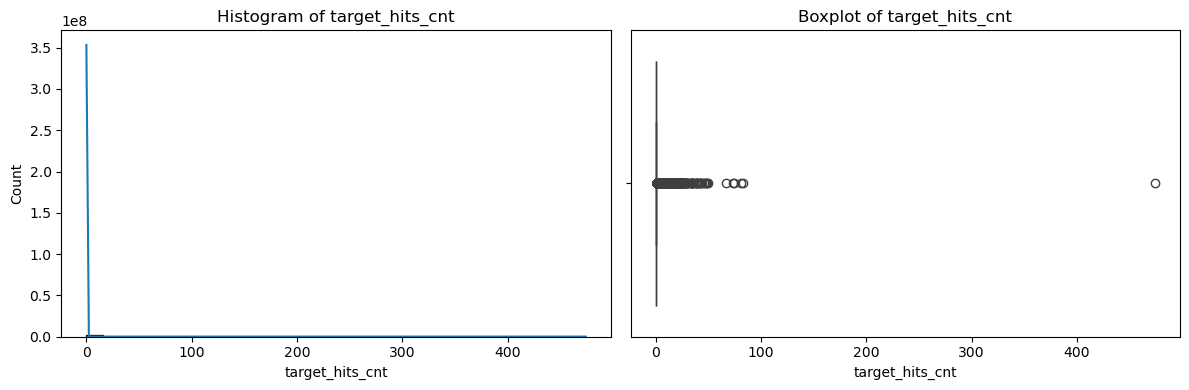

In [13]:
plot_cols = ["visit_number", "hits_cnt", "unique_pages", "unique_actions", "target_hits_cnt"]

for col in plot_cols:
    if col in df.columns:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        sns.histplot(df[col], bins=30, kde=True, ax=axes[0])
        axes[0].set_title(f"Histogram of {col}")

        sns.boxplot(x=df[col], ax=axes[1])
        axes[1].set_title(f"Boxplot of {col}")

        plt.tight_layout()
        plt.show()

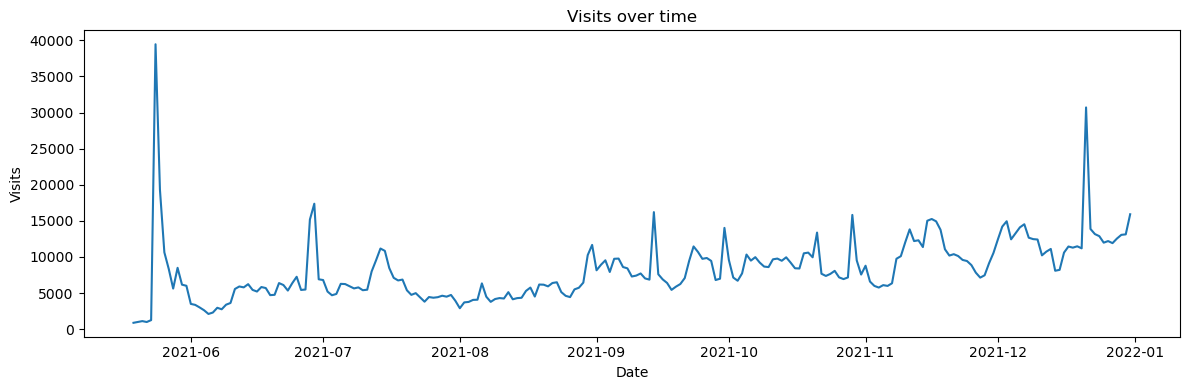

In [14]:
if "visit_date" in df.columns:
    visits_over_time = df.groupby(df["visit_date"].dt.date).size().reset_index(name="visits")
    visits_over_time.columns = ["date", "visits"]

    plt.figure(figsize=(12, 4))
    plt.plot(pd.to_datetime(visits_over_time["date"]), visits_over_time["visits"])
    plt.title("Visits over time")
    plt.xlabel("Date")
    plt.ylabel("Visits")
    plt.tight_layout()
    plt.show()

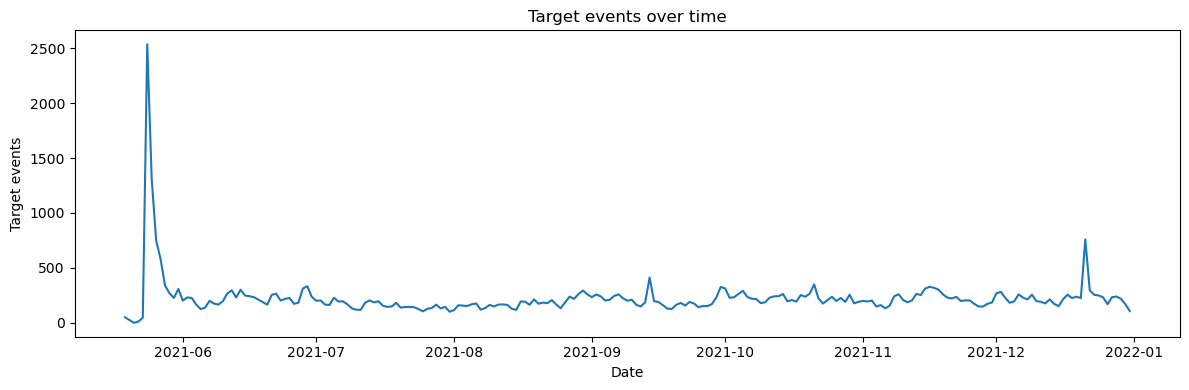

In [15]:
if "visit_date" in df.columns:
    target_over_time = df.groupby(df["visit_date"].dt.date)["target"].sum().reset_index()
    target_over_time.columns = ["date", "target_events"]

    plt.figure(figsize=(12, 4))
    plt.plot(pd.to_datetime(target_over_time["date"]), target_over_time["target_events"])
    plt.title("Target events over time")
    plt.xlabel("Date")
    plt.ylabel("Target events")
    plt.tight_layout()
    plt.show()

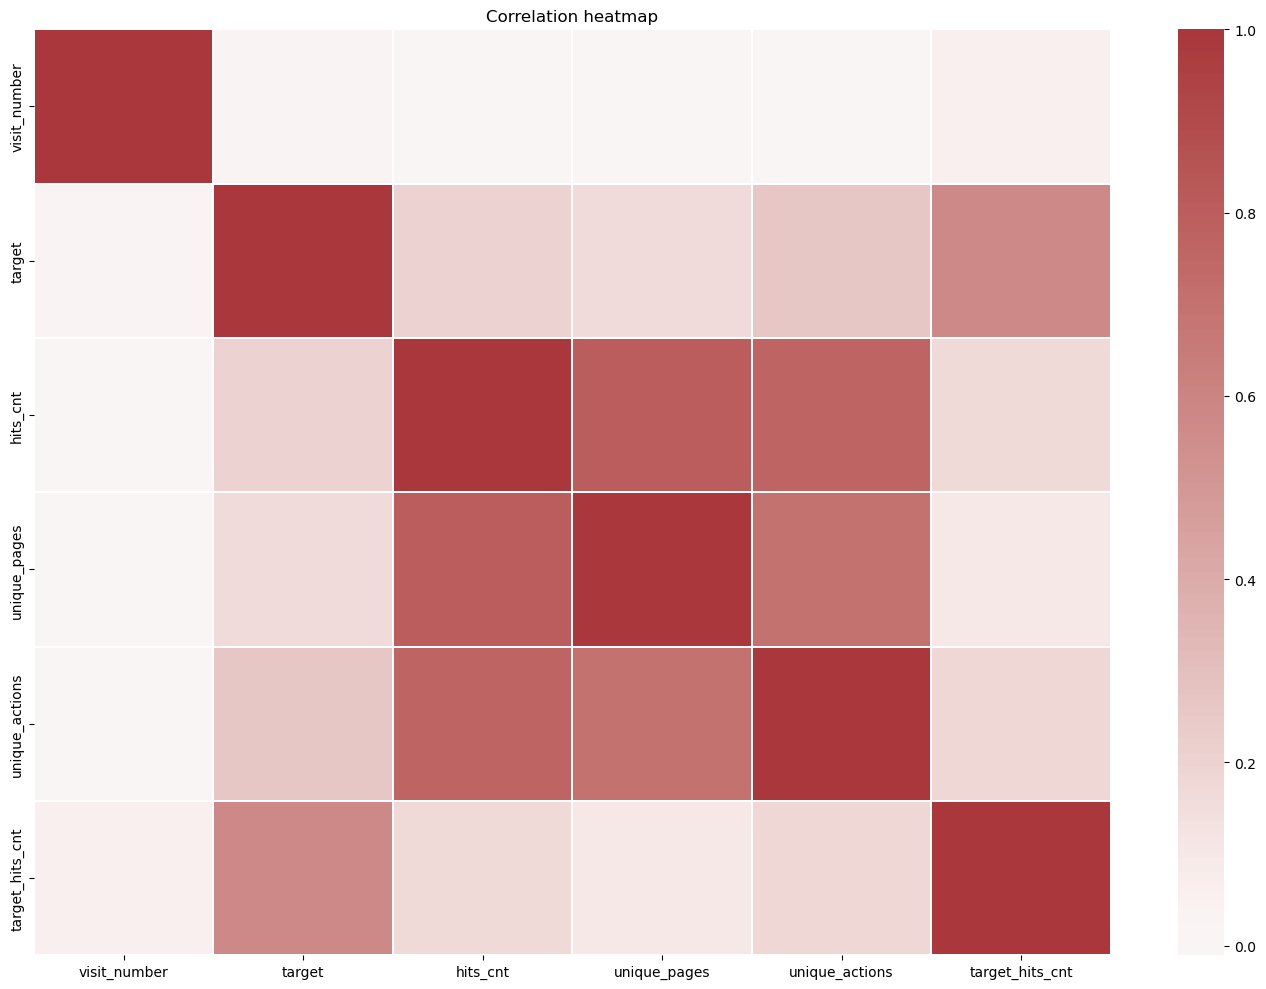

In [16]:
numeric_df = df.select_dtypes(include=[np.number]).copy()
corr = numeric_df.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap="vlag", center=0, linewidths=0.2)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

In [17]:
corr_pairs = (corr.abs().unstack().sort_values(ascending=False))
corr_pairs = corr_pairs[corr_pairs < 1].drop_duplicates()
display(corr_pairs.head(20))

unique_pages     hits_cnt           0.808512
hits_cnt         unique_actions     0.765179
unique_actions   unique_pages       0.697266
target           target_hits_cnt    0.572542
                 unique_actions     0.264868
                 hits_cnt           0.204888
unique_actions   target_hits_cnt    0.184193
target_hits_cnt  hits_cnt           0.168802
target           unique_pages       0.164858
target_hits_cnt  unique_pages       0.102503
visit_number     target_hits_cnt    0.056877
                 target             0.025320
unique_actions   visit_number       0.010349
visit_number     hits_cnt           0.001148
                 unique_pages       0.000475
dtype: float64

In [18]:
print("Выводы:")
print("1. Данные содержат пропуски и дубликаты, поэтому требуется очистка.")
print("2. Таргет сильно зависит от агрегатов по hits и временных признаков.")
print("3. Распределения многих числовых признаков асимметричны и содержат выбросы.")
print("4. Корреляционная матрица помогает выявить дублирующие признаки.")

Выводы:
1. Данные содержат пропуски и дубликаты, поэтому требуется очистка.
2. Таргет сильно зависит от агрегатов по hits и временных признаков.
3. Распределения многих числовых признаков асимметричны и содержат выбросы.
4. Корреляционная матрица помогает выявить дублирующие признаки.
